# MSCS 634 - Lab Assignment 6

**Name:** Chun-Shuo Sheu
**Course:** MSCS 634 - Big Data & Data Mining
**Lab Assignment:** Lab 6 - Association Rule Mining with Apriori and FP-Growth

## Overview
In this lab we perform **association rule mining** on the *Online Retail* dataset from the
UCI Machine Learning Repository - roughly 542,000 real transaction line items from a UK-based
online gift retailer between December 2010 and December 2011.

The workflow is:

1. **Data preparation** - clean the raw transaction log and reshape it into a one-hot encoded
   basket matrix, with Seaborn visualizations that describe the data.
2. **Apriori** - mine frequent itemsets using the classic breadth-first, candidate-generation algorithm.
3. **FP-Growth** - mine the same frequent itemsets using the FP-tree based algorithm and compare runtimes.
4. **Association rules** - derive rules from the frequent itemsets and analyze them with
   support, confidence and lift.
5. **Comparative analysis** - discuss the algorithms' relative efficiency and the challenges encountered.

## Step 1: Data Preparation

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 160)

# --- Mining parameters (justified in the markdown cells below) ---
TOP_N_ITEMS    = 600     # keep the 600 most frequently sold products (verified lossless below)
MIN_SUPPORT    = 0.015   # an itemset must appear in >= 1.5% of transactions
MIN_CONFIDENCE = 0.50    # a rule must hold at least 50% of the time

print(f"pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}")

pandas 3.0.5 | numpy 2.5.1 | seaborn 0.13.2


### 1.1 Load the raw transaction log

The dataset ships with this notebook as `online_retail.csv.gz` (a gzip-compressed copy of the
original UCI `Online Retail.xlsx` file, so the notebook runs without a network connection).
Each row is a single **line item** on an invoice, so one invoice spans many rows - exactly the
item-level transactional format that Apriori and FP-Growth require.

In [2]:
df_raw = pd.read_csv('online_retail.csv.gz', compression='gzip', parse_dates=['InvoiceDate'])

print(f"Raw shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Date range: {df_raw['InvoiceDate'].min()} to {df_raw['InvoiceDate'].max()}")
df_raw.head()

Raw shape: 541,909 rows x 8 columns
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
print("Column types and missing values:")
summary = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'missing': df_raw.isna().sum(),
    'missing_%': (df_raw.isna().mean() * 100).round(2),
    'n_unique': df_raw.nunique()
})
summary

Column types and missing values:


,dtype,missing,missing_%,n_unique
InvoiceNo,str,0,0.00,25900
StockCode,str,0,0.00,4070
Description,str,1454,0.27,4223
Quantity,int64,0,0.00,722
InvoiceDate,datetime64[us],0,0.00,23260
UnitPrice,float64,0,0.00,1630
CustomerID,float64,135080,24.93,4372
Country,str,0,0.00,38


### 1.2 Data cleaning

The raw log contains several kinds of records that would corrupt the mined patterns, so we remove them:

| Issue | Why it matters for association rule mining | Action |
|---|---|---|
| Missing `Description` | The item name is the mining "item"; a null cannot be part of an itemset | Drop the row |
| Cancelled invoices (`InvoiceNo` starting with `C`) | These are *returns*, i.e. the negation of a purchase | Drop the row |
| `Quantity <= 0` or `UnitPrice <= 0` | Refunds, write-offs and free give-aways are not purchase decisions | Drop the row |
| Non-product entries (`POSTAGE`, `MANUAL`, `BANK CHARGES`, ...) | These are fees/adjustments, not products; they co-occur with everything and produce meaningless rules | Drop the row |
| Same item listed twice on one invoice | Basket analysis is about *presence*, not quantity - a duplicate would double-count | De-duplicate on (`InvoiceNo`, `Description`) |
| Single-item invoices | A basket of one item cannot contribute to any co-occurrence pattern | Drop the invoice |

We also normalize `Description` to stripped upper case, because the same product appears with
inconsistent spacing/casing in the raw file.

In [4]:
df = df_raw.copy()
steps = []
def log(step, frame):
    steps.append({'Cleaning step': step,
                  'Rows remaining': len(frame),
                  'Invoices remaining': frame['InvoiceNo'].nunique()})

df['InvoiceNo'] = df['InvoiceNo'].astype(str)
log('0. Raw data', df)

# 1. Rows with no product description cannot be used as items.
df = df.dropna(subset=['Description'])
log('1. Drop missing Description', df)

# 2. Normalise the product name so the same product maps to one item label.
df['Description'] = df['Description'].str.strip().str.upper()

# 3. Cancellations / credit notes are returns, not purchases.
df = df[~df['InvoiceNo'].str.startswith('C')]
log('2. Drop cancelled invoices', df)

# 4. Non-positive quantity or price = refund, write-off or free sample.
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
log('3. Drop non-positive qty/price', df)

# 5. Administrative / non-product entries.
NON_PRODUCT_DESC = {
    'POSTAGE', 'DOTCOM POSTAGE', 'MANUAL', 'DISCOUNT', 'CARRIAGE', 'BANK CHARGES',
    'AMAZON FEE', 'CRUK COMMISSION', 'SAMPLES', 'ADJUST BAD DEBT',
    'NEXT DAY CARRIAGE', 'HIGH RESOLUTION IMAGE', 'FOUND', 'CHECK', 'DAMAGED'
}
NON_PRODUCT_CODES = {'POST', 'D', 'M', 'DOT', 'C2', 'S', 'B', 'BANK CHARGES', 'AMAZONFEE', 'CRUK', 'PADS'}
df = df[~df['Description'].isin(NON_PRODUCT_DESC)]
df = df[~df['StockCode'].astype(str).str.upper().isin(NON_PRODUCT_CODES)]
log('4. Drop non-product entries', df)

# 6. Basket analysis cares about presence, not repeated lines of the same product.
df = df.drop_duplicates(subset=['InvoiceNo', 'Description'])
log('5. De-duplicate (invoice, item)', df)

# 7. An invoice with a single item cannot support any co-occurrence pattern.
basket_sizes = df.groupby('InvoiceNo')['Description'].size()
df = df[df['InvoiceNo'].isin(basket_sizes[basket_sizes >= 2].index)]
log('6. Drop single-item invoices', df)

pd.DataFrame(steps)

,Cleaning step,Rows remaining,Invoices remaining
0,0. Raw data,541909,25900
1,1. Drop missing Description,540455,24446
2,2. Drop cancelled invoices,531167,20610
3,3. Drop non-positive qty/price,530104,19960
4,4. Drop non-product entries,527707,19770
5,"5. De-duplicate (invoice, item)",516945,19770
6,6. Drop single-item invoices,515442,18267


In [5]:
n_tx    = df['InvoiceNo'].nunique()
n_items = df['Description'].nunique()
sizes   = df.groupby('InvoiceNo')['Description'].size()

print(f"Transactions (invoices) : {n_tx:,}")
print(f"Distinct products       : {n_items:,}")
print(f"Total line items        : {len(df):,}")
print(f"Countries               : {df['Country'].nunique()}")
print(f"Rows removed by cleaning: {len(df_raw) - len(df):,} "
      f"({(1 - len(df) / len(df_raw)) * 100:.1f}% of the raw file)")
print()
print("Items per transaction:")
sizes.describe().round(2)

Transactions (invoices) : 18,267
Distinct products       : 3,998
Total line items        : 515,442
Countries               : 38
Rows removed by cleaning: 26,467 (4.9% of the raw file)

Items per transaction:


count    18267.00
mean        28.22
std         48.30
min          2.00
25%          8.00
50%         17.00
75%         30.00
max       1107.00
Name: Description, dtype: float64

### 1.3 Exploratory visualizations

Three views of the cleaned data: which products sell most often, how large a typical basket is,
and which products tend to show up together.

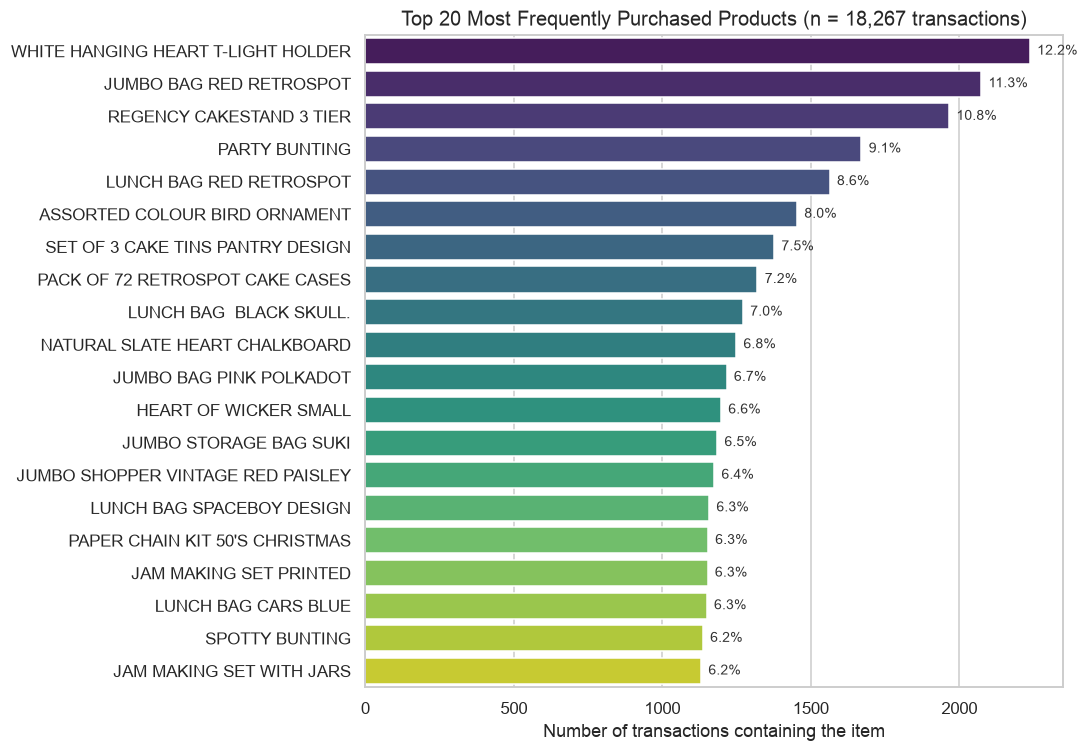

In [6]:
top20 = df['Description'].value_counts().head(20).reset_index()
top20.columns = ['Item', 'Transactions']
top20['Support'] = top20['Transactions'] / n_tx

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=top20, y='Item', x='Transactions', hue='Item',
            palette='viridis', legend=False, ax=ax)
for i, (cnt, sup) in enumerate(zip(top20['Transactions'], top20['Support'])):
    ax.text(cnt + 25, i, f'{sup:.1%}', va='center', fontsize=9, color='#333')
ax.set_title(f'Top 20 Most Frequently Purchased Products (n = {n_tx:,} transactions)', fontsize=13)
ax.set_xlabel('Number of transactions containing the item')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig('top_items.png', dpi=120, bbox_inches='tight')
plt.show()

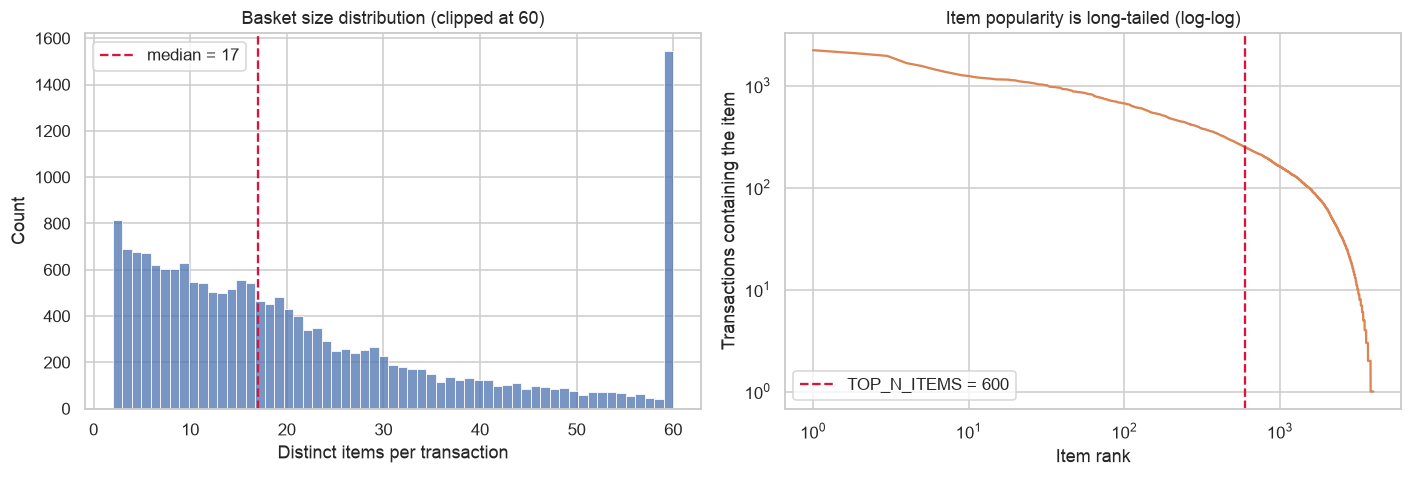

The 600 most popular items account for 56.0% of all line items, out of 3,998 distinct products.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(sizes.clip(upper=60), bins=59, color='#4C72B0', ax=axes[0])
axes[0].axvline(sizes.median(), color='crimson', ls='--',
                label=f'median = {sizes.median():.0f}')
axes[0].set_title('Basket size distribution (clipped at 60)')
axes[0].set_xlabel('Distinct items per transaction')
axes[0].legend()

item_freq = df['Description'].value_counts().to_numpy()
axes[1].plot(np.arange(1, len(item_freq) + 1), item_freq, color='#DD8452')
axes[1].axvline(TOP_N_ITEMS, color='crimson', ls='--', label=f'TOP_N_ITEMS = {TOP_N_ITEMS}')
axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_title('Item popularity is long-tailed (log-log)')
axes[1].set_xlabel('Item rank'); axes[1].set_ylabel('Transactions containing the item')
axes[1].legend()

plt.tight_layout()
plt.savefig('data_distributions.png', dpi=120, bbox_inches='tight')
plt.show()

print(f"The {TOP_N_ITEMS} most popular items account for "
      f"{item_freq[:TOP_N_ITEMS].sum() / item_freq.sum():.1%} of all line items, "
      f"out of {n_items:,} distinct products.")

The right-hand plot is the key modelling justification: item popularity follows a steep long tail.
Of the ~4,000 distinct products, the great majority appear in only a handful of invoices, so a full
4,000-column basket matrix would be mostly dead weight - and Apriori's candidate generation scales
badly in the number of items.

We therefore restrict the matrix to the **top 600 products**. Crucially, this is not an arbitrary
cut: it is chosen so that the restriction is **lossless at our support threshold**. The cell after
the basket construction verifies that the most popular *excluded* item still falls below
`MIN_SUPPORT`, which means no frequent itemset is lost - any itemset containing an excluded item
would be even rarer than that item itself. The mined results are therefore exactly what we would
have obtained from the full 4,000-item matrix, just computed far more cheaply.

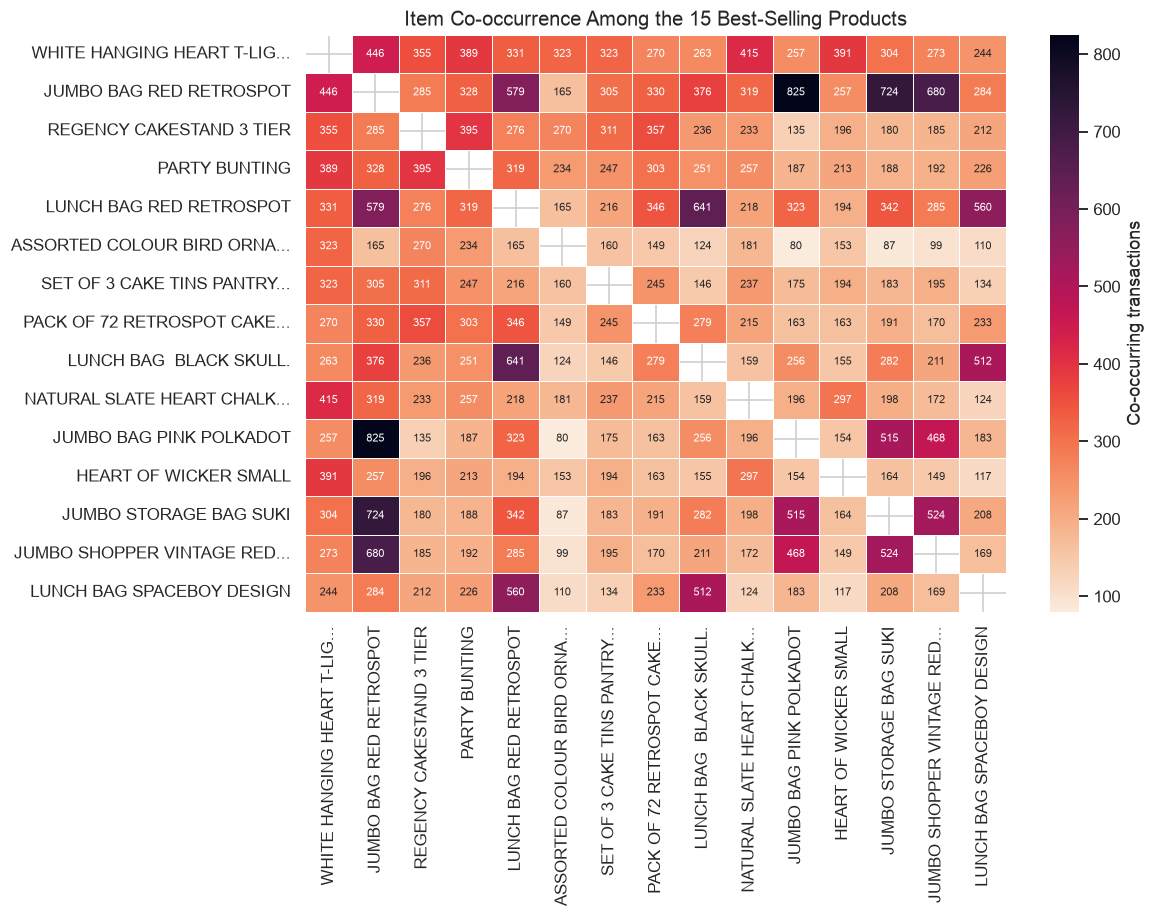

In [8]:
# Co-occurrence heatmap for the 15 best-selling items
top15 = df['Description'].value_counts().head(15).index
sub15 = df[df['Description'].isin(top15)]
mat15 = (sub15.assign(v=1)
              .pivot_table(index='InvoiceNo', columns='Description', values='v', fill_value=0)
              .astype(int))
mat15 = mat15.reindex(columns=top15)          # keep popularity order
cooc = mat15.T @ mat15                        # counts; diagonal = item frequency

short = [c if len(c) <= 28 else c[:25] + '...' for c in cooc.columns]
cooc.index = cooc.columns = short

mask = np.eye(len(cooc), dtype=bool)          # hide the diagonal so the pairs set the colour scale
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(cooc, mask=mask, cmap='rocket_r', annot=True, fmt='d',
            annot_kws={'size': 7}, linewidths=.5, cbar_kws={'label': 'Co-occurring transactions'}, ax=ax)
ax.set_title('Item Co-occurrence Among the 15 Best-Selling Products', fontsize=13)
ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout()
plt.savefig('cooccurrence_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

The heatmap already hints at the structure the algorithms will formalise. The brightest cells sit
inside product *families*: the **JUMBO BAG** range (RED RETROSPOT with PINK POLKADOT, STORAGE BAG
SUKI and VINTAGE RED PAISLEY) and the **LUNCH BAG** range (RED RETROSPOT with BLACK SKULL and
SPACEBOY). Customers who buy one variant of a design very often buy another variant of the same
design in the same order. Cross-family cells - a lunch bag with a cake tin, say - are noticeably paler.

Note also that `JUMBO BAG RED RETROSPOT` is bright against *many* items. That is partly because it is
simply the most popular product in the catalogue, which is exactly the trap that raw co-occurrence
counts fall into and that the **lift** metric in Step 4 will correct for.

### 1.4 Build the one-hot encoded basket matrix

Apriori and FP-Growth in `mlxtend` expect a boolean matrix with one row per transaction and one
column per item. We restrict to the top 200 products (justified above) and re-apply the
"at least 2 items" rule, since a few invoices lose all but one of their items in the restriction.

In [9]:
top_items = df['Description'].value_counts().head(TOP_N_ITEMS).index
sub = df[df['Description'].isin(top_items)]

keep = sub.groupby('InvoiceNo')['Description'].size()
sub = sub[sub['InvoiceNo'].isin(keep[keep >= 2].index)]

basket = (sub.assign(v=1)
             .pivot_table(index='InvoiceNo', columns='Description', values='v', fill_value=0)
             .astype(bool))

n_basket_tx = basket.shape[0]
print(f"Basket matrix: {basket.shape[0]:,} transactions x {basket.shape[1]} items")
print(f"Density (fraction of True cells): {basket.to_numpy().mean():.4f}")
print(f"MIN_SUPPORT = {MIN_SUPPORT} corresponds to at least "
      f"{int(np.ceil(MIN_SUPPORT * n_basket_tx))} transactions")
basket.iloc[:5, :6]

Basket matrix: 17,027 transactions x 600 items
Density (fraction of True cells): 0.0282
MIN_SUPPORT = 0.015 corresponds to at least 256 transactions


Description,10 COLOUR SPACEBOY PEN,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE RED RETROSPOT,12 PENCILS TALL TUBE SKULLS
InvoiceNo,,,,,,
536365,False,False,False,False,False,False
536367,False,False,False,False,False,False
536370,False,False,False,False,False,False
536373,False,False,False,False,False,False
536375,False,False,False,False,False,False


In [10]:
# Verify the top-600 restriction is LOSSLESS at MIN_SUPPORT.
# An itemset can never be more frequent than its rarest item, so if the most popular EXCLUDED
# item cannot reach MIN_SUPPORT, then no itemset containing an excluded item can either.
item_counts = df['Description'].value_counts()
excluded_max_count   = item_counts.iloc[TOP_N_ITEMS]        # most popular item we dropped
excluded_max_support = excluded_max_count / n_basket_tx

print(f"Most popular EXCLUDED item appears in {excluded_max_count} transactions")
print(f"  -> its maximum possible support = {excluded_max_support:.5f}")
print(f"  -> MIN_SUPPORT                  = {MIN_SUPPORT:.5f}")
print()
if excluded_max_support < MIN_SUPPORT:
    print("LOSSLESS: no excluded item can reach MIN_SUPPORT, so no frequent itemset is lost.")
    print("The results below are identical to mining the full 3,998-item matrix.")
else:
    print("WARNING: an excluded item could clear MIN_SUPPORT - increase TOP_N_ITEMS.")

print(f"\nItems retained that clear MIN_SUPPORT on their own: "
      f"{int((basket.sum() / n_basket_tx >= MIN_SUPPORT).sum())}")
print(f"Share of all line items covered by the top {TOP_N_ITEMS} products: "
      f"{item_counts.head(TOP_N_ITEMS).sum() / item_counts.sum():.1%}")

Most popular EXCLUDED item appears in 250 transactions
  -> its maximum possible support = 0.01468
  -> MIN_SUPPORT                  = 0.01500

LOSSLESS: no excluded item can reach MIN_SUPPORT, so no frequent itemset is lost.
The results below are identical to mining the full 3,998-item matrix.

Items retained that clear MIN_SUPPORT on their own: 575
Share of all line items covered by the top 600 products: 56.0%


**Choosing the support threshold.** A threshold of **1.5%** (about 255 of the ~17,000 transactions)
is low enough to surface multi-item patterns of length 3-4, but high enough that each pattern rests
on a few hundred real baskets rather than on noise. Thresholds above ~4% collapse the output to a
handful of trivial pairs, while 0.5% produces ~25,000 itemsets that are impossible to interpret.
The sweep in Step 3 shows this trade-off explicitly.

## Step 2: Frequent Itemset Mining Using Apriori

Apriori works breadth-first. It finds all frequent 1-itemsets, generates 2-itemset candidates from
them, scans the database to count support, prunes the infrequent ones, and repeats for length 3, 4, ...
Its pruning rule is the *Apriori property*: any superset of an infrequent itemset is itself infrequent.

In [11]:
t0 = time.perf_counter()
freq_apriori = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True)
apriori_time = time.perf_counter() - t0

freq_apriori['length'] = freq_apriori['itemsets'].apply(len)
freq_apriori = freq_apriori.sort_values('support', ascending=False).reset_index(drop=True)

print(f"Apriori found {len(freq_apriori):,} frequent itemsets "
      f"at min_support = {MIN_SUPPORT} in {apriori_time:.3f} seconds")

Apriori found 1,013 frequent itemsets at min_support = 0.015 in 8.717 seconds


In [12]:
def fmt_itemset(s, width=55):
    txt = ', '.join(sorted(s))
    return txt if len(txt) <= width else txt[:width - 3] + '...'

view = freq_apriori.copy()
view['itemsets'] = view['itemsets'].apply(fmt_itemset)
print("Top 15 frequent itemsets by support (Apriori):")
view.head(15)

Top 15 frequent itemsets by support (Apriori):


,support,itemsets,length
0,0.130616,WHITE HANGING HEART T-LIGHT HOLDER,1
1,0.121572,JUMBO BAG RED RETROSPOT,1
2,0.114524,REGENCY CAKESTAND 3 TIER,1
3,0.097786,PARTY BUNTING,1
4,0.091737,LUNCH BAG RED RETROSPOT,1
5,0.085041,ASSORTED COLOUR BIRD ORNAMENT,1
6,0.080578,SET OF 3 CAKE TINS PANTRY DESIGN,1
7,0.077465,PACK OF 72 RETROSPOT CAKE CASES,1
8,0.074646,LUNCH BAG BLACK SKULL.,1
9,0.073119,NATURAL SLATE HEART CHALKBOARD,1


In [13]:
by_len = (freq_apriori.groupby('length')
          .agg(itemsets=('support', 'size'),
               min_support=('support', 'min'),
               max_support=('support', 'max'))
          .reset_index()
          .rename(columns={'length': 'Itemset size'}))
by_len[['min_support', 'max_support']] = by_len[['min_support', 'max_support']].round(4)
print("Frequent itemsets by size (Apriori):")
by_len

Frequent itemsets by size (Apriori):


,Itemset size,itemsets,min_support,max_support
0,1,575,0.0150,0.1306
1,2,365,0.0150,0.0485
2,3,70,0.0150,0.0318
3,4,3,0.0153,0.0177


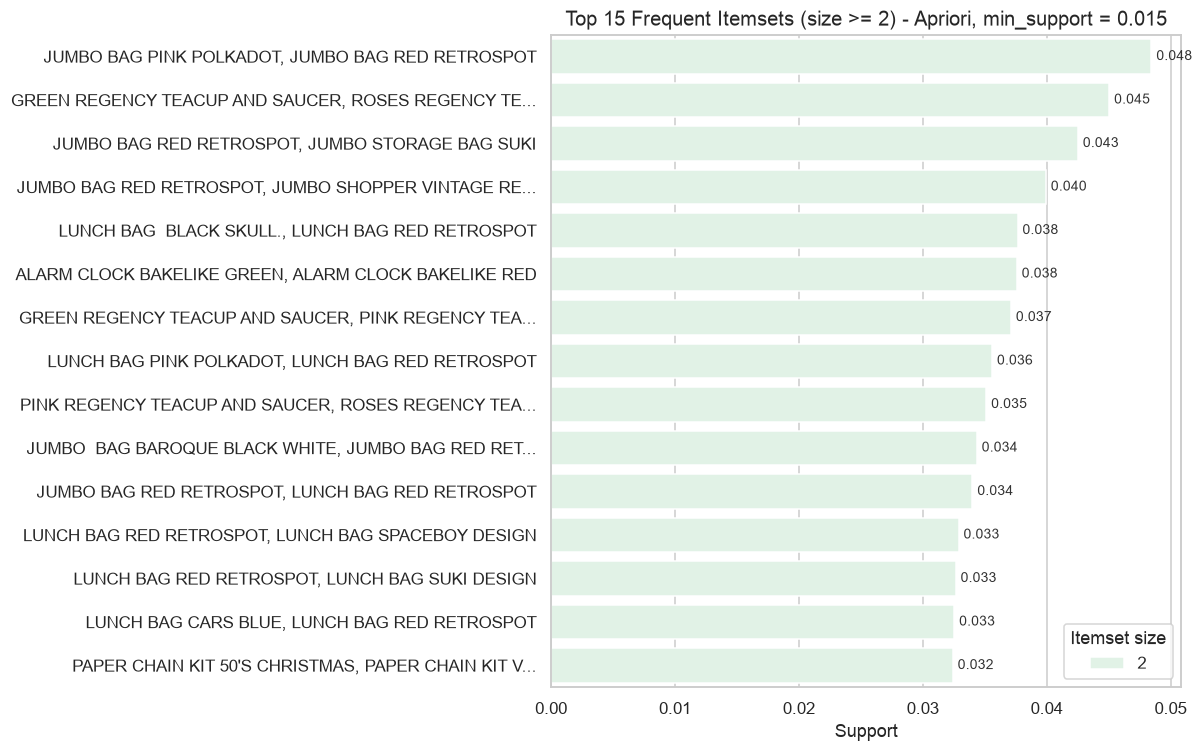

In [14]:
# Top 15 *multi-item* itemsets - length-1 itemsets are just item frequencies and carry no association info
top_sets = (freq_apriori[freq_apriori['length'] >= 2]
            .nlargest(15, 'support').copy())
top_sets['label'] = top_sets['itemsets'].apply(fmt_itemset, width=52)

fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(data=top_sets, y='label', x='support', hue='length',
            palette='mako_r', dodge=False, ax=ax)
for i, s in enumerate(top_sets['support']):
    ax.text(s + 0.0004, i, f'{s:.3f}', va='center', fontsize=9, color='#333')
ax.set_title(f'Top 15 Frequent Itemsets (size >= 2) - Apriori, min_support = {MIN_SUPPORT}', fontsize=13)
ax.set_xlabel('Support'); ax.set_ylabel('')
ax.legend(title='Itemset size', loc='lower right')
plt.tight_layout()
plt.savefig('apriori_itemsets.png', dpi=120, bbox_inches='tight')
plt.show()

## Step 3: Frequent Itemset Mining Using FP-Growth

FP-Growth avoids candidate generation entirely. It compresses the whole database into a
**FP-tree** (a prefix tree of frequency-ordered transactions) in two passes, then recursively mines
conditional FP-trees. We apply the **same** `MIN_SUPPORT = 0.015` so the two result sets are directly comparable.

In [15]:
t0 = time.perf_counter()
freq_fpgrowth = fpgrowth(basket, min_support=MIN_SUPPORT, use_colnames=True)
fpgrowth_time = time.perf_counter() - t0

freq_fpgrowth['length'] = freq_fpgrowth['itemsets'].apply(len)
freq_fpgrowth = freq_fpgrowth.sort_values('support', ascending=False).reset_index(drop=True)

print(f"FP-Growth found {len(freq_fpgrowth):,} frequent itemsets "
      f"at min_support = {MIN_SUPPORT} in {fpgrowth_time:.3f} seconds")
print(f"Apriori   : {len(freq_apriori):,} itemsets in {apriori_time:.3f} s")
print(f"Speed-up  : {apriori_time / fpgrowth_time:.2f}x faster with FP-Growth")

FP-Growth found 1,013 frequent itemsets at min_support = 0.015 in 1.466 seconds
Apriori   : 1,013 itemsets in 8.717 s
Speed-up  : 5.95x faster with FP-Growth


In [16]:
# Do the two algorithms return exactly the same answer?
a_sets = set(freq_apriori['itemsets'])
f_sets = set(freq_fpgrowth['itemsets'])
print(f"Identical set of itemsets : {a_sets == f_sets}")
print(f"Only in Apriori           : {len(a_sets - f_sets)}")
print(f"Only in FP-Growth         : {len(f_sets - a_sets)}")

merged = (freq_apriori[['itemsets', 'support']]
          .merge(freq_fpgrowth[['itemsets', 'support']], on='itemsets', suffixes=('_apriori', '_fpgrowth')))
max_diff = (merged['support_apriori'] - merged['support_fpgrowth']).abs().max()
print(f"Max support difference    : {max_diff:.2e}")

Identical set of itemsets : True
Only in Apriori           : 0
Only in FP-Growth         : 0
Max support difference    : 0.00e+00


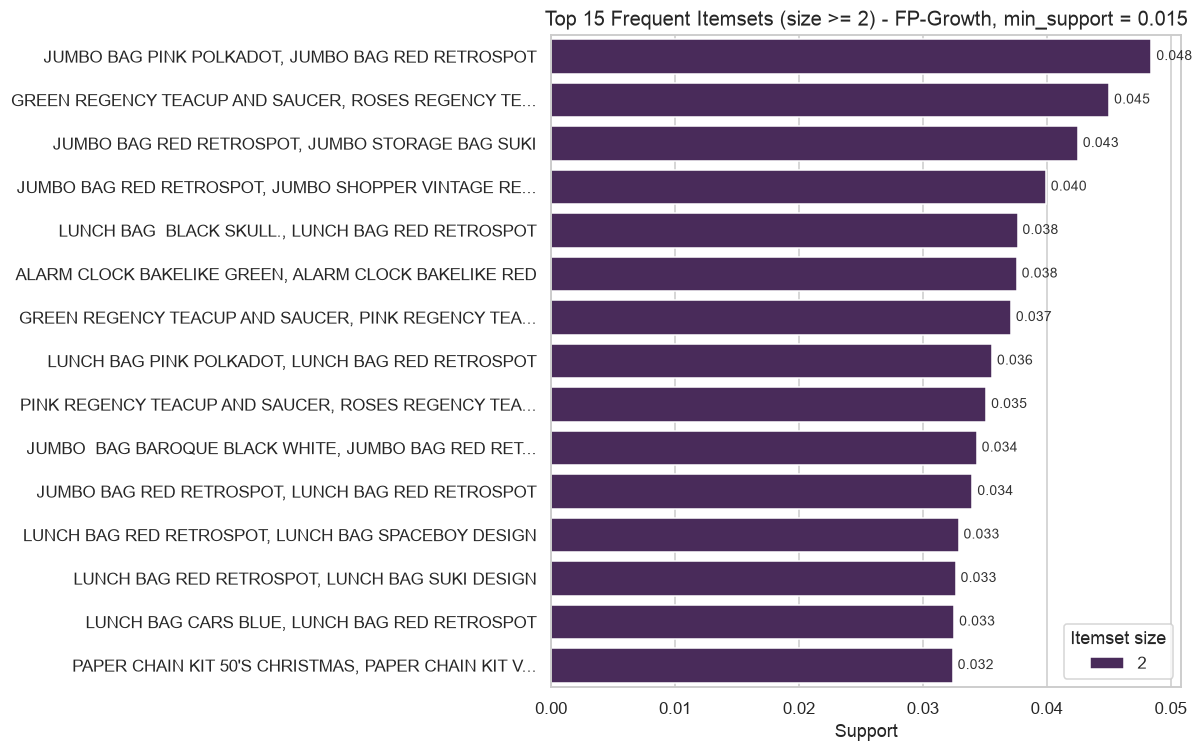

In [17]:
top_sets_fp = (freq_fpgrowth[freq_fpgrowth['length'] >= 2]
               .nlargest(15, 'support').copy())
top_sets_fp['label'] = top_sets_fp['itemsets'].apply(fmt_itemset, width=52)

fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(data=top_sets_fp, y='label', x='support', hue='length',
            palette='flare_r', dodge=False, ax=ax)
for i, s in enumerate(top_sets_fp['support']):
    ax.text(s + 0.0004, i, f'{s:.3f}', va='center', fontsize=9, color='#333')
ax.set_title(f'Top 15 Frequent Itemsets (size >= 2) - FP-Growth, min_support = {MIN_SUPPORT}', fontsize=13)
ax.set_xlabel('Support'); ax.set_ylabel('')
ax.legend(title='Itemset size', loc='lower right')
plt.tight_layout()
plt.savefig('fpgrowth_itemsets.png', dpi=120, bbox_inches='tight')
plt.show()

The two bar charts are identical, which is the expected result: Apriori and FP-Growth are exact
algorithms that enumerate the *same* complete set of frequent itemsets. They differ only in **how**
they get there, and therefore in runtime.

### 3.1 Runtime comparison across support thresholds

A single timing at one threshold is not very informative, so we sweep the support threshold and
time both algorithms (best of 3 runs each) to see where the difference actually comes from.

In [18]:
SUPPORT_GRID = [0.05, 0.04, 0.03, 0.02, 0.015, 0.01, 0.0075, 0.005]
REPEATS = 3

def best_of(fn, min_support, repeats=REPEATS):
    """Run `fn` `repeats` times and return (result, fastest elapsed time)."""
    best, result = float('inf'), None
    for _ in range(repeats):
        t0 = time.perf_counter()
        result = fn(basket, min_support=min_support, use_colnames=True)
        best = min(best, time.perf_counter() - t0)
    return result, best

records = []
for ms in SUPPORT_GRID:
    _, ta = best_of(apriori, ms)
    res_fp, tf = best_of(fpgrowth, ms)
    n = len(res_fp)
    records.append({'min_support': ms, 'n_itemsets': n,
                    'Apriori (s)': ta, 'FP-Growth (s)': tf, 'Speed-up': ta / tf})
    print(f"min_support={ms:<7} itemsets={n:>6,}  apriori={ta:6.3f}s  fpgrowth={tf:6.3f}s  ({ta / tf:.2f}x)")

timing = pd.DataFrame(records)
timing.round({'Apriori (s)': 3, 'FP-Growth (s)': 3, 'Speed-up': 2})

min_support=0.05    itemsets=    54  apriori= 0.054s  fpgrowth= 0.118s  (0.45x)


min_support=0.04    itemsets=    98  apriori= 0.157s  fpgrowth= 0.198s  (0.79x)


min_support=0.03    itemsets=   209  apriori= 0.542s  fpgrowth= 0.374s  (1.45x)


min_support=0.02    itemsets=   532  apriori= 2.614s  fpgrowth= 0.991s  (2.64x)


min_support=0.015   itemsets= 1,013  apriori= 7.244s  fpgrowth= 1.600s  (4.53x)


min_support=0.01    itemsets= 2,428  apriori= 8.255s  fpgrowth= 1.782s  (4.63x)


min_support=0.0075  itemsets= 5,877  apriori= 9.485s  fpgrowth= 2.159s  (4.39x)


min_support=0.005   itemsets=25,121  apriori=22.354s  fpgrowth= 4.675s  (4.78x)


,min_support,n_itemsets,Apriori (s),FP-Growth (s),Speed-up
0,0.0500,54,0.054,0.118,0.45
1,0.0400,98,0.157,0.198,0.79
2,0.0300,209,0.542,0.374,1.45
3,0.0200,532,2.614,0.991,2.64
4,0.0150,1013,7.244,1.600,4.53
5,0.0100,2428,8.255,1.782,4.63
6,0.0075,5877,9.485,2.159,4.39
7,0.0050,25121,22.354,4.675,4.78


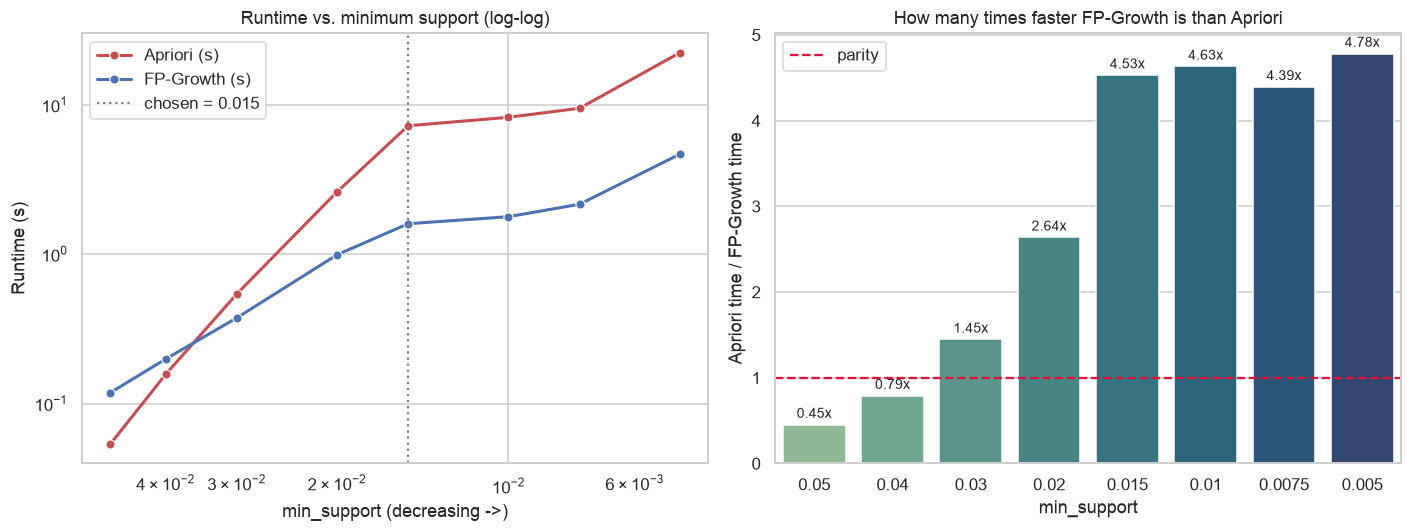

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

long = timing.melt(id_vars='min_support', value_vars=['Apriori (s)', 'FP-Growth (s)'],
                   var_name='Algorithm', value_name='Runtime (s)')
sns.lineplot(data=long, x='min_support', y='Runtime (s)', hue='Algorithm',
             marker='o', linewidth=2, palette=['#C44E52', '#4C72B0'], ax=axes[0])
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].invert_xaxis()
axes[0].axvline(MIN_SUPPORT, color='grey', ls=':', label=f'chosen = {MIN_SUPPORT}')
axes[0].set_title('Runtime vs. minimum support (log-log)')
axes[0].set_xlabel('min_support (decreasing ->)')
axes[0].legend()

sns.barplot(data=timing, x=timing['min_support'].astype(str), y='Speed-up',
            hue=timing['min_support'].astype(str), palette='crest', legend=False, ax=axes[1])
axes[1].axhline(1.0, color='crimson', ls='--', label='parity')
for i, v in enumerate(timing['Speed-up']):
    axes[1].text(i, v + 0.08, f'{v:.2f}x', ha='center', fontsize=9)
axes[1].set_title('How many times faster FP-Growth is than Apriori')
axes[1].set_xlabel('min_support'); axes[1].set_ylabel('Apriori time / FP-Growth time')
axes[1].legend()

plt.tight_layout()
plt.savefig('runtime_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

This is the clearest result in the lab. At **high** support thresholds the two algorithms are
essentially tied - there are so few frequent items that Apriori's candidate generation barely does
any work, and FP-Growth still has to pay the fixed cost of building the FP-tree. As the threshold
drops, Apriori's cost explodes because the number of candidate itemsets it must generate and count
grows combinatorially and it re-scans the database once per itemset length. FP-Growth builds its
tree once and mines it recursively, so its cost grows far more gently.

## Step 4: Generating and Analyzing Association Rules

An itemset only tells us *what* occurs together. A rule `X -> Y` adds direction and strength:

- **Support**  = P(X and Y) - how often the whole pattern occurs. High support = commercially relevant.
- **Confidence** = P(Y | X) - how often the rule is correct when X is present. High confidence = reliable.
- **Lift** = confidence / P(Y) - how much more likely Y is given X than at random.
  Lift > 1 means positive association; lift = 1 means independence; lift < 1 means substitution.

Confidence alone is misleading, because a very popular consequent gets high confidence from *any*
antecedent. Lift corrects for that, so we rank by lift and require `confidence >= 0.50`.

In [20]:
rules = association_rules(freq_fpgrowth, metric='confidence', min_threshold=MIN_CONFIDENCE)
rules['antecedent_len'] = rules['antecedents'].apply(len)
rules['consequent_len'] = rules['consequents'].apply(len)
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)

print(f"{len(rules):,} rules with confidence >= {MIN_CONFIDENCE} "
      f"and support >= {MIN_SUPPORT}")
print(f"Support    range: {rules['support'].min():.4f} - {rules['support'].max():.4f}")
print(f"Confidence range: {rules['confidence'].min():.3f} - {rules['confidence'].max():.3f}")
print(f"Lift       range: {rules['lift'].min():.2f} - {rules['lift'].max():.2f}")
print(f"All rules have lift > 1: {(rules['lift'] > 1).all()}")

348 rules with confidence >= 0.5 and support >= 0.015
Support    range: 0.0150 - 0.0485
Confidence range: 0.500 - 0.911
Lift       range: 4.12 - 40.84
All rules have lift > 1: True


In [21]:
# Verify that rules derived from the Apriori itemsets are the same
rules_apriori = association_rules(freq_apriori, metric='confidence', min_threshold=MIN_CONFIDENCE)
key = lambda r: set(zip(r['antecedents'], r['consequents']))
print(f"Rules from Apriori itemsets   : {len(rules_apriori):,}")
print(f"Rules from FP-Growth itemsets : {len(rules):,}")
print(f"Identical rule sets           : {key(rules_apriori) == key(rules)}")

Rules from Apriori itemsets   : 348
Rules from FP-Growth itemsets : 348
Identical rule sets           : True


In [22]:
def rules_table(frame, n=15):
    out = pd.DataFrame({
        'Antecedent (if bought)': frame['antecedents'].apply(fmt_itemset, width=45),
        'Consequent (then bought)': frame['consequents'].apply(fmt_itemset, width=45),
        'support': frame['support'].round(4),
        'confidence': frame['confidence'].round(3),
        'lift': frame['lift'].round(2),
    })
    return out.head(n).reset_index(drop=True)

print("Top 15 rules by LIFT (strongest associations):")
rules_table(rules, 15)

Top 15 rules by LIFT (strongest associations):


,Antecedent (if bought),Consequent (then bought),support,confidence,lift
0,REGENCY TEA PLATE PINK,REGENCY TEA PLATE GREEN,0.0163,0.911,40.84
1,REGENCY TEA PLATE GREEN,REGENCY TEA PLATE PINK,0.0163,0.732,40.84
2,REGENCY TEA PLATE ROSES,REGENCY TEA PLATE PINK,0.0158,0.610,34.05
3,REGENCY TEA PLATE PINK,REGENCY TEA PLATE ROSES,0.0158,0.882,34.05
4,REGENCY TEA PLATE GREEN,REGENCY TEA PLATE ROSES,0.0187,0.839,32.41
5,REGENCY TEA PLATE ROSES,REGENCY TEA PLATE GREEN,0.0187,0.723,32.41
6,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE LIVINGROOM,0.0153,0.615,31.91
7,POPPY'S PLAYHOUSE LIVINGROOM,POPPY'S PLAYHOUSE BEDROOM,0.0153,0.793,31.91
8,POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE LIVINGROOM,0.0154,0.601,31.19
9,POPPY'S PLAYHOUSE LIVINGROOM,POPPY'S PLAYHOUSE KITCHEN,0.0154,0.799,31.19


In [23]:
print("Top 15 rules by CONFIDENCE (most reliable predictions):")
rules_table(rules.sort_values('confidence', ascending=False), 15)

Top 15 rules by CONFIDENCE (most reliable predictions):


,Antecedent (if bought),Consequent (then bought),support,confidence,lift
0,REGENCY TEA PLATE PINK,REGENCY TEA PLATE GREEN,0.0163,0.911,40.84
1,"PINK REGENCY TEACUP AND SAUCER, REGENCY CA...",GREEN REGENCY TEACUP AND SAUCER,0.0177,0.909,15.30
2,"PINK REGENCY TEACUP AND SAUCER, ROSES REGE...",GREEN REGENCY TEACUP AND SAUCER,0.0318,0.905,15.22
3,"SET/20 RED RETROSPOT PAPER NAPKINS, SET/6 ...",SET/6 RED SPOTTY PAPER PLATES,0.0156,0.895,28.93
4,REGENCY TEA PLATE PINK,REGENCY TEA PLATE ROSES,0.0158,0.882,34.05
5,"GREEN REGENCY TEACUP AND SAUCER, PINK REGE...",ROSES REGENCY TEACUP AND SAUCER,0.0177,0.878,14.11
6,"PINK REGENCY TEACUP AND SAUCER, REGENCY CA...",GREEN REGENCY TEACUP AND SAUCER,0.0201,0.875,14.72
7,"JUMBO BAG PINK POLKADOT, JUMBO SHOPPER VIN...",JUMBO BAG RED RETROSPOT,0.0157,0.867,7.13
8,"CHARLOTTE BAG PINK POLKADOT, STRAWBERRY CH...",RED RETROSPOT CHARLOTTE BAG,0.0191,0.860,14.21
9,"CHARLOTTE BAG SUKI DESIGN, STRAWBERRY CHAR...",RED RETROSPOT CHARLOTTE BAG,0.0153,0.858,14.17


In [24]:
print("Top 15 rules by SUPPORT (most commercially frequent patterns):")
rules_table(rules.sort_values('support', ascending=False), 15)

Top 15 rules by SUPPORT (most commercially frequent patterns):


,Antecedent (if bought),Consequent (then bought),support,confidence,lift
0,JUMBO BAG PINK POLKADOT,JUMBO BAG RED RETROSPOT,0.0485,0.679,5.59
1,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.0450,0.758,12.19
2,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.0450,0.724,12.19
3,JUMBO STORAGE BAG SUKI,JUMBO BAG RED RETROSPOT,0.0425,0.611,5.03
4,JUMBO SHOPPER VINTAGE RED PAISLEY,JUMBO BAG RED RETROSPOT,0.0399,0.579,4.76
5,LUNCH BAG BLACK SKULL.,LUNCH BAG RED RETROSPOT,0.0376,0.504,5.50
6,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE GREEN,0.0376,0.611,10.69
7,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,0.0376,0.657,10.69
8,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.0371,0.625,13.99
9,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.0371,0.832,13.99


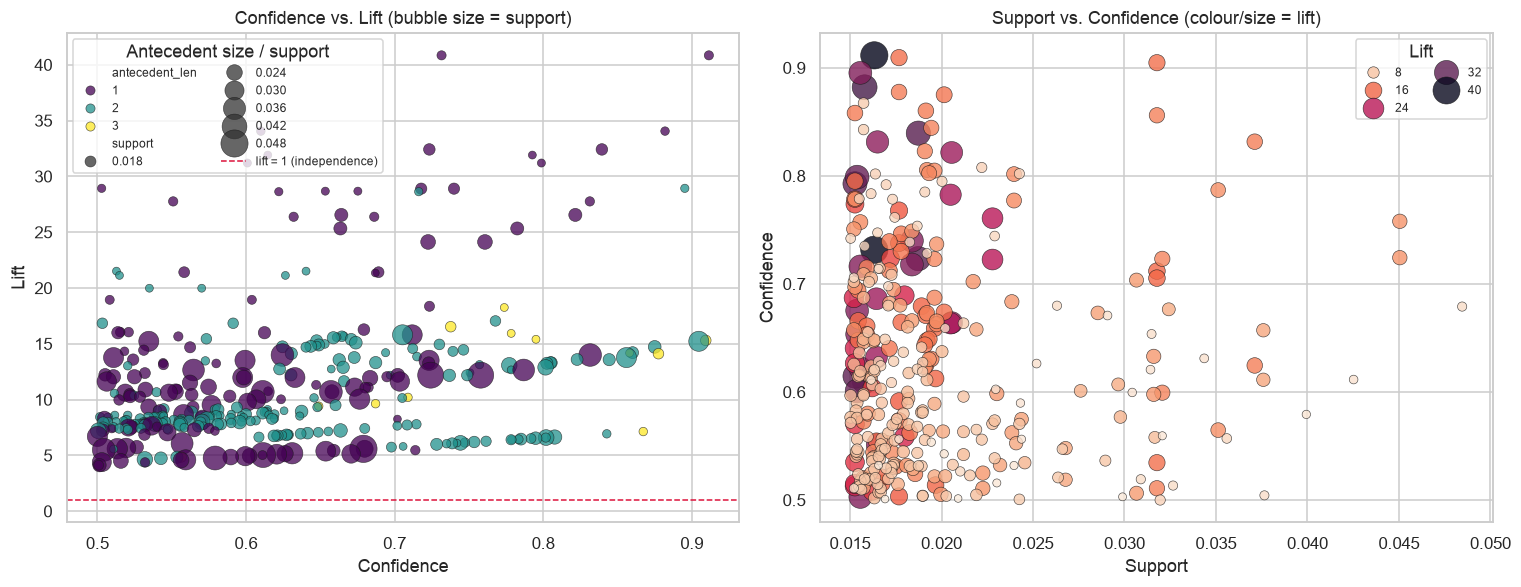

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sc = sns.scatterplot(data=rules, x='confidence', y='lift', size='support',
                     hue='antecedent_len', palette='viridis', sizes=(25, 320),
                     alpha=0.75, edgecolor='k', linewidth=0.4, ax=axes[0])
axes[0].axhline(1.0, color='crimson', ls='--', lw=1, label='lift = 1 (independence)')
axes[0].set_title('Confidence vs. Lift (bubble size = support)', fontsize=12)
axes[0].set_xlabel('Confidence'); axes[0].set_ylabel('Lift')
axes[0].legend(title='Antecedent size / support', fontsize=8, loc='upper left', ncols=2)

sns.scatterplot(data=rules, x='support', y='confidence', hue='lift',
                palette='rocket_r', size='lift', sizes=(25, 320),
                alpha=0.8, edgecolor='k', linewidth=0.4, ax=axes[1])
axes[1].set_title('Support vs. Confidence (colour/size = lift)', fontsize=12)
axes[1].set_xlabel('Support'); axes[1].set_ylabel('Confidence')
axes[1].legend(title='Lift', fontsize=8, loc='upper right', ncols=2)

plt.tight_layout()
plt.savefig('rules_scatter.png', dpi=120, bbox_inches='tight')
plt.show()

The left panel is the rule-selection map. Every rule sits above the red `lift = 1` line, so all of
them describe genuine positive associations rather than coincidences of popularity. The most
valuable rules are the ones in the **upper-right** - high confidence *and* high lift - and among
those the large bubbles are the ones that also occur often enough to act on.

There is a visible trade-off in the right panel: the highest-support rules (right side) have only
moderate lift, because they involve popular items that co-occur partly by volume alone, while the
highest-lift rules (dark points) sit at lower support - they are niche but extremely predictive.

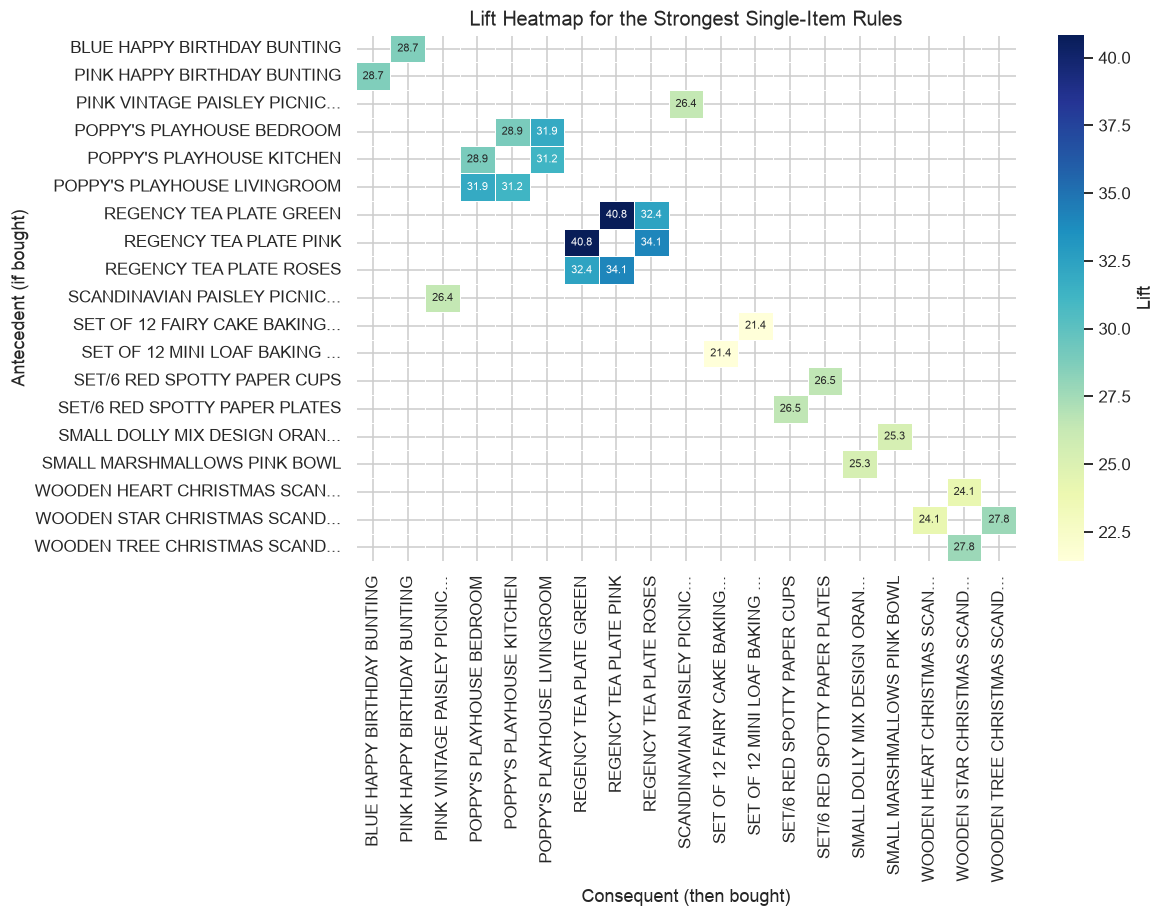

In [26]:
# A heatmap of lift for the strongest single-item -> single-item rules
pairs = rules[(rules['antecedent_len'] == 1) & (rules['consequent_len'] == 1)].copy()
pairs['a'] = pairs['antecedents'].apply(lambda s: next(iter(s)))
pairs['c'] = pairs['consequents'].apply(lambda s: next(iter(s)))

focus = pairs.nlargest(25, 'lift')
labels = sorted(set(focus['a']) | set(focus['c']))
piv = pairs[pairs['a'].isin(labels) & pairs['c'].isin(labels)].pivot_table(
    index='a', columns='c', values='lift').reindex(index=labels, columns=labels)
piv.index = [l if len(l) <= 30 else l[:27] + '...' for l in piv.index]
piv.columns = [l if len(l) <= 30 else l[:27] + '...' for l in piv.columns]

fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(piv, cmap='YlGnBu', annot=True, fmt='.1f', annot_kws={'size': 7},
            linewidths=.5, cbar_kws={'label': 'Lift'}, ax=ax)
ax.set_title('Lift Heatmap for the Strongest Single-Item Rules', fontsize=13)
ax.set_xlabel('Consequent (then bought)'); ax.set_ylabel('Antecedent (if bought)')
plt.tight_layout()
plt.savefig('lift_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

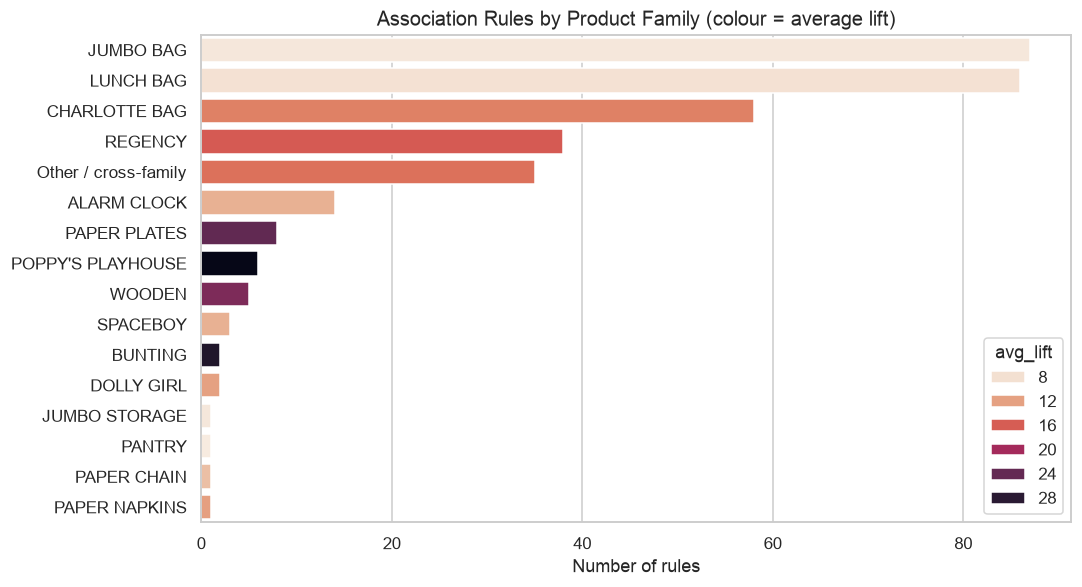

,rules,avg_lift,avg_conf,max_support
family,,,,
JUMBO BAG,87,7.533,0.629,0.048
LUNCH BAG,86,7.865,0.571,0.038
CHARLOTTE BAG,58,13.951,0.654,0.031
REGENCY,38,16.196,0.700,0.045
Other / cross-family,35,14.863,0.596,0.032
ALARM CLOCK,14,11.026,0.655,0.038
PAPER PLATES,8,24.187,0.710,0.022
POPPY'S PLAYHOUSE,6,30.667,0.711,0.018
WOODEN,5,22.484,0.685,0.032


In [27]:
# What product families do the rules describe? Group rules by the keyword shared by their items.
def family(rule_items):
    words = ["POPPY'S PLAYHOUSE", 'CHARLOTTE BAG', 'JUMBO BAG', 'JUMBO SHOPPER', 'JUMBO STORAGE',
             'LUNCH BAG', 'REGENCY', 'ALARM CLOCK', 'PAPER PLATES', 'PAPER NAPKINS', 'PAPER CUPS',
             'HERB MARKER', 'WOODEN', 'CAKE STAND', 'PANTRY', 'DOLLY GIRL',
             'SPACEBOY', 'CHILDRENS CUTLERY', 'PAPER CHAIN', 'BUNTING']
    items = ' | '.join(rule_items)
    for w in words:
        if w in items:
            return w
    return 'Other / cross-family'

rules['family'] = rules.apply(lambda r: family(list(r['antecedents']) + list(r['consequents'])), axis=1)
fam = (rules.groupby('family')
       .agg(rules=('lift', 'size'), avg_lift=('lift', 'mean'), avg_conf=('confidence', 'mean'),
            max_support=('support', 'max'))
       .sort_values('rules', ascending=False).round(3))

fig, ax = plt.subplots(figsize=(10, 5.5))
plot_df = fam.reset_index()
sns.barplot(data=plot_df, y='family', x='rules', hue='avg_lift',
            palette='rocket_r', dodge=False, ax=ax)
ax.set_title('Association Rules by Product Family (colour = average lift)', fontsize=13)
ax.set_xlabel('Number of rules'); ax.set_ylabel('')
plt.tight_layout()
plt.savefig('rules_by_family.png', dpi=120, bbox_inches='tight')
plt.show()

fam

### 4.1 Interpretation of the mined rules

**1. The dominant pattern is *variant completion*, not cross-category basket building.**
Almost every high-lift rule connects different colours or prints of the *same* product line - the
REGENCY tea range, the POPPY'S PLAYHOUSE rooms, the CHARLOTTE / JUMBO / LUNCH BAG ranges, the
BAKELIKE alarm clocks. Customers here are not filling a mixed basket; they are collecting a **set**.
The strongest rule in the whole output is
`REGENCY TEA PLATE PINK -> REGENCY TEA PLATE GREEN` at **91% confidence and lift 40.8**: a customer
who buys the pink plate is forty times likelier than chance to also buy the green one. The
POPPY'S PLAYHOUSE dolls-house rooms behave the same way (lift ~29-32) - buying the bedroom strongly
predicts buying the kitchen and the living room.

**2. Strong rules are largely bidirectional, but not symmetric in confidence.** For most strong
pairs, both `X -> Y` and `Y -> X` clear the threshold with the same lift (lift is symmetric by
definition), yet their confidences differ sharply: `PINK -> GREEN` tea plate holds 91% of the time
while `GREEN -> PINK` holds only 73%. The reason is that the green plate is the more popular of the
two, so it has more baskets in which the pink one is absent. This is precisely why the analysis
ranks by lift but reports confidence alongside it - the *direction* you would act on is the
high-confidence one.

**3. High confidence does not imply high lift - the "popular hub" effect.** Several rules point at
`JUMBO BAG RED RETROSPOT`, the single best-selling product, with confidence up to 87%
(e.g. `JUMBO BAG PINK POLKADOT, JUMBO SHOPPER VINTAGE RED PAISLEY -> JUMBO BAG RED RETROSPOT`).
But their lift is only ~5-7, far below the tea-plate rules. Much of that confidence comes from the
consequent simply being everywhere, not from a genuine affinity. A recommender tuned on confidence
alone would spend its slots promoting the item customers were most likely to buy anyway; ranking by
lift avoids that.

**4. Longer antecedents give higher confidence but lower support.** The highest-confidence rules
(over 90%) have 2-3 item antecedents from within a single family - once a customer has already put
two REGENCY teacups in the basket, the third is nearly certain. These are excellent
"complete the set" recommendations, but each applies to a smaller slice of traffic, which is the
support/confidence trade-off visible in the right-hand scatter plot.

**5. Practical actions the rules support:**
- *Bundling / kitting* - sell the REGENCY tea plates and the POPPY'S PLAYHOUSE rooms as
  pre-packaged sets, since customers are already assembling them by hand.
- *Recommendation widgets* - the high-confidence multi-item rules are exactly what a
  "customers who bought these also bought" panel needs, and they fire late in basket building,
  when a recommendation is most likely to convert.
- *Inventory co-planning* - because the associations are strong and bidirectional, stocking out one
  variant will depress sales of its siblings. These families should be re-ordered together rather
  than managed as independent SKUs.
- *What the rules do **not** support* - there are very few genuine cross-family rules above the
  threshold, so recommending an unrelated category on the strength of this data would not be
  evidence-driven.

**6. A caution on causality.** These are co-occurrence patterns, not causal effects. Part of the
lift on variant pairs comes from the site's own layout - variants of a design are typically shown on
the same product page, so they co-occur partly *because* they are displayed together. The rules also
describe a single retailer over a single year, including one Christmas season, so they are seasonal
as well as site-specific. Validating a rule would require an A/B test, not a larger mining run.

## Step 5: Comparative Analysis

In [28]:
comparison = pd.DataFrame({
    'Metric': [
        'Frequent itemsets found',
        'Max itemset length',
        'Runtime at min_support = %.3f (s)' % MIN_SUPPORT,
        'Runtime at min_support = 0.005 (s)',
        'Association rules generated',
        'Search strategy',
        'Database scans',
        'Candidate generation',
    ],
    'Apriori': [
        f"{len(freq_apriori):,}",
        int(freq_apriori['length'].max()),
        f"{apriori_time:.3f}",
        f"{timing.loc[timing['min_support'] == 0.005, 'Apriori (s)'].iloc[0]:.3f}",
        f"{len(rules_apriori):,}",
        'Breadth-first (level-wise)',
        'One per itemset length (k scans)',
        'Yes - explicit candidate sets',
    ],
    'FP-Growth': [
        f"{len(freq_fpgrowth):,}",
        int(freq_fpgrowth['length'].max()),
        f"{fpgrowth_time:.3f}",
        f"{timing.loc[timing['min_support'] == 0.005, 'FP-Growth (s)'].iloc[0]:.3f}",
        f"{len(rules):,}",
        'Depth-first (divide and conquer)',
        'Two (build FP-tree, then mine it)',
        'No - mines a compressed tree',
    ],
})
comparison

,Metric,Apriori,FP-Growth
0,Frequent itemsets found,"1,013","1,013"
1,Max itemset length,4,4
2,Runtime at min_support = 0.015 (s),8.717,1.466
3,Runtime at min_support = 0.005 (s),22.354,4.675
4,Association rules generated,348,348
5,Search strategy,Breadth-first (level-wise),Depth-first (divide and conquer)
6,Database scans,One per itemset length (k scans),"Two (build FP-tree, then mine it)"
7,Candidate generation,Yes - explicit candidate sets,No - mines a compressed tree


### Which algorithm was faster, and why?

**FP-Growth was faster**, and its advantage widened sharply as the support threshold dropped.
Apriori actually *wins* at very high thresholds (`min_support = 0.05`, `0.04`), the two cross over
around `min_support = 0.03`, and from there FP-Growth pulls away to roughly **4x** faster at the
chosen `min_support = 0.015` and stays there down to `0.005`. (Absolute timings vary with machine
load; the *ratio* and the shape of the curve are the stable findings.)

The reason is structural:

- **Apriori re-scans the database once per itemset length.** To find frequent 4-itemsets it must
  scan the 15,000 x 200 basket matrix a fourth time, after generating and testing every candidate
  4-itemset built from the frequent 3-itemsets. The number of candidates grows combinatorially as
  the threshold falls, and most of them turn out to be infrequent - work that is thrown away.
- **FP-Growth scans the database exactly twice** - once to count item frequencies, once to build the
  FP-tree - and then never touches the raw data again. All subsequent mining happens on the tree.
- **The FP-tree exploits prefix sharing, and this dataset has a lot of it.** Because the strong
  patterns live inside product families, many transactions share long prefixes once items are sorted
  by frequency, so the tree compresses the database substantially and the recursive mining stays cheap.
- **FP-Growth never generates a candidate that turns out to be infrequent.** Every itemset it
  enumerates is frequent by construction, so it does no wasted counting.

The one place Apriori is competitive is at *high* support thresholds: there are so few frequent
items that candidate generation is trivial, while FP-Growth still pays the fixed cost of building
the tree. That is exactly the crossover visible in the runtime plot. FP-Growth's cost is the extra
memory for the tree, which was not a constraint at this scale but would be on a dataset that does
not fit comfortably in RAM.

**Both algorithms produced exactly the same output** - identical itemsets, identical supports to
floating-point precision, and identical rule sets. This is the expected behaviour: they are both
*exact* algorithms for the same problem, so the choice between them is purely about efficiency,
never about result quality.

### Challenges faced and how they were resolved

**1. Dirty transaction records.** The raw file mixes real purchases with cancellations
(`InvoiceNo` starting with `C`), refunds, zero-price give-aways, and administrative entries like
`POSTAGE`, `MANUAL` and `BANK CHARGES`. Left in, the administrative entries are especially damaging:
`POSTAGE` appears on a large share of invoices, so it forms a high-support itemset with almost every
product and floods the rule list with meaningless patterns. *Resolution:* an explicit blacklist of
non-product descriptions and stock codes, plus filters for cancelled invoices and non-positive
quantity/price. The cleaning log shows each step's effect on the row count.

**2. Dimensionality of the basket matrix, and doing the reduction *honestly*.** After cleaning there
are ~4,000 distinct products, so a full one-hot matrix would be 18,000 x 4,000 - and Apriori's
candidate generation degrades badly as the item count grows. The obvious fix is to keep only the
most popular items, but my first attempt used the top 200 purely because it "looked like enough,"
and that turned out to be wrong: checking afterwards, **531 items clear the 1.5% support threshold
on the full data**, so a top-200 cut would have silently discarded genuinely frequent items and
produced an incomplete rule set. *Resolution:* choose the cut-off from the threshold instead of by
eye. With `TOP_N_ITEMS = 600`, the most popular *excluded* item reaches at most ~1.47% support -
below `MIN_SUPPORT` - and since an itemset can never be more frequent than its rarest item, no
frequent itemset can contain an excluded item. The restriction is therefore provably **lossless**
at this threshold: the results equal those of the full 4,000-item matrix, but compute in seconds.
The notebook verifies this explicitly rather than asserting it.

**3. Choosing the support threshold.** The first attempt at `min_support = 0.05` returned only a few
dozen itemsets, all of length 1-2 - nothing worth interpreting. Dropping to `0.005` returned
~25,000 itemsets, far too many to interpret, and Apriori took over 30 seconds. *Resolution:* rather
than guessing, I swept the threshold and used the results to pick `0.015`, which yields ~1,000
itemsets up to length 4 - enough structure to be interesting, few enough to interpret.

**4. Duplicate line items within one invoice.** The same product can appear on several lines of one
invoice (different price tiers or manual corrections). One-hot encoding by summing quantities would
have produced values greater than 1 and silently broken the boolean encoding `mlxtend` expects.
*Resolution:* de-duplicate on (`InvoiceNo`, `Description`) before pivoting, and cast the pivot
explicitly to `bool`.

**5. Making the timing comparison trustworthy.** A single timed call is noisy enough that the
Apriori/FP-Growth ordering could flip between runs at high support thresholds. *Resolution:* time
best-of-3 runs across a grid of eight thresholds and plot the whole curve, so the conclusion rests
on a trend rather than on one measurement.

**6. Reading rules that are dominated by near-duplicates.** Because the product families are tightly
coupled, the top of the lift ranking is filled with permutations of the same 4-5 Charlotte bag
prints, which obscures the broader picture. *Resolution:* group the rules by product family and
report the families alongside the individual rules, and inspect the ranking by lift, confidence and
support separately - each ordering surfaces a different kind of insight.

## Conclusion

Association rule mining on the Online Retail dataset produced **1,013 frequent itemsets** (up to
length 4) at 1.5% support and **348 rules** at 50% confidence, every one of them with lift above 1
(minimum 4.1). Because the top-600 item restriction was verified lossless at this threshold, that is
the complete set of frequent itemsets for the cleaned catalogue, not a sample of it.

The commercial story is consistent and clear: this retailer's customers buy **within product
families**, collecting variants of a single design, with the strongest pair - the pink and green
REGENCY tea plates - reaching a lift of **40.8** at 91% confidence.

On the algorithmic side, Apriori and FP-Growth returned provably identical results, so the
comparison is purely about efficiency - and FP-Growth won decisively wherever the problem was hard,
scaling far better as the support threshold fell because it replaces repeated database scans and
combinatorial candidate generation with a single compressed FP-tree.